In [1]:
# ============================================================================
# IEEE ACCESS PAPER: HiENBERT - Hybrid Indic-English BERT for Multi-Task 
# Complaint Classification with Sentiment-Enhanced Severity Prediction
# ============================================================================
# CELL 1: IMPORTS AND SYSTEM SETUP

import os
import sys
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.optim import AdamW
from torch.cuda.amp import GradScaler, autocast

# Transformers
from transformers import (
    AutoTokenizer, 
    AutoModel,
    XLMRobertaModel,
    XLMRobertaTokenizer,
    XLMRobertaConfig,
    get_cosine_schedule_with_warmup,
    get_linear_schedule_with_warmup
)

# Scikit-learn
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, 
    f1_score, 
    precision_score, 
    recall_score,
    classification_report, 
    confusion_matrix,
    roc_auc_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = True  # Enable for faster training

set_seed(42)

# Device configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    torch.backends.cudnn.benchmark = True
print(f"Using device: {device}")
print(f"{'='*80}\n")


SYSTEM INFORMATION
PyTorch version: 2.5.1+cu121
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [ ]:
# ============================================================================
# CELL 2: CONFIGURATION
# ============================================================================

class Config:
    """Configuration settings for HiENBERT training with optimized performance"""
    
    # Model selection - Choose base model
    # Options: 'indicbert' or 'xlm-roberta'
    BASE_MODEL = 'indicbert'  # Change to 'xlm-roberta' for XLM-RoBERTa base
    
    # Model paths
    INDICBERT_PATH = "ai4bharat/indic-bert"
    XLMBERT_PATH = "xlm-roberta-base"
    
    # Training params - Optimized for speed
    MAX_LENGTH = 128
    BATCH_SIZE = 32  # Increased for faster training
    EPOCHS = 20
    LEARNING_RATE = 2e-5
    DROPOUT = 0.3
    WEIGHT_DECAY = 0.01
    GRADIENT_ACCUMULATION_STEPS = 1  # Reduced for faster training
    WARMUP_RATIO = 0.1
    
    # Mixed precision training
    USE_AMP = True  # Automatic Mixed Precision for faster training
    
    # Imbalance handling - Carefully designed to not create more imbalance
    USE_CLASS_WEIGHTS = True
    USE_FOCAL_LOSS = True
    USE_WEIGHTED_SAMPLER = True
    FOCAL_ALPHA = 0.25
    FOCAL_GAMMA = 2.0
    
    # Severity enhancement - Preserve original distribution
    ENHANCE_SEVERITY = True
    SENTIMENT_THRESHOLD = 0.3
    
    # Data paths
    DATA_DIR = "dataset"
    TRAIN_PATH = f"{DATA_DIR}/train/train.csv"
    DEV_PATH = f"{DATA_DIR}/dev/dev.csv"
    TEST_PATH = f"{DATA_DIR}/test/test.csv"
    
    # Output directories
    BASE_DIR = f"hienbert_{BASE_MODEL}_results"
    MODEL_DIR = f"{BASE_DIR}/models"
    VISUALIZATION_DIR = f"{BASE_DIR}/visualizations"
    LOG_DIR = f"{BASE_DIR}/logs"
    RESULTS_DIR = f"{BASE_DIR}/results"
    
    # Create directories
    for dir_path in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, LOG_DIR, RESULTS_DIR]:
        os.makedirs(dir_path, exist_ok=True)
    
    # Device
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Random seed
    SEED = 42
    
    # HuggingFace token
    HF_TOKEN = os.getenv("HF_TOKEN")

# Get model path based on selection
def get_model_path():
    if Config.BASE_MODEL == 'indicbert':
        return Config.INDICBERT_PATH
    elif Config.BASE_MODEL == 'xlm-roberta':
        return Config.XLMBERT_PATH
    else:
        raise ValueError(f"Unsupported base model: {Config.BASE_MODEL}")

print(f"Configuration loaded successfully")
print(f"Base Model: {Config.BASE_MODEL}")
print(f"Model Path: {get_model_path()}")
print(f"Results will be saved to: {Config.BASE_DIR}")
print(f"\nImbalance Handling:")
print(f"  Class Weights: {Config.USE_CLASS_WEIGHTS}")
print(f"  Focal Loss: {Config.USE_FOCAL_LOSS}")
print(f"  Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")
print(f"\nPerformance Optimization:")
print(f"  Mixed Precision: {Config.USE_AMP}")
print(f"  Batch Size: {Config.BATCH_SIZE}")

Configuration loaded successfully
Base Model: indicbert
Model Path: ai4bharat/indic-bert
Results will be saved to: hienbert_indicbert_results

Imbalance Handling:
  Class Weights: True
  Focal Loss: True
  Weighted Sampler: True

Performance Optimization:
  Mixed Precision: True
  Batch Size: 32


In [3]:
# ============================================================================
# CELL 3: DATA LOADING WITH IMBALANCE ANALYSIS
# ============================================================================

class DataLoaderWithImbalance:
    """Load data and analyze class imbalance - preserving original distribution"""
    
    def __init__(self):
        self.train_df = None
        self.dev_df = None
        self.test_df = None
        self.class_weights = {}
        self.original_distribution = {}
        
    def load_data(self):
        """Load train, dev, test datasets"""
        print("Loading datasets...")
        
        self.train_df = pd.read_csv(Config.TRAIN_PATH)
        self.dev_df = pd.read_csv(Config.DEV_PATH)
        self.test_df = pd.read_csv(Config.TEST_PATH)
        
        print(f"Train samples: {len(self.train_df)}")
        print(f"Dev samples: {len(self.dev_df)}")
        print(f"Test samples: {len(self.test_df)}")
        
        return self.train_df, self.dev_df, self.test_df
    
    def analyze_imbalance(self, df, label_col, title=""):
        """Analyze and visualize class imbalance"""
        class_counts = df[label_col].value_counts()
        class_percentages = df[label_col].value_counts(normalize=True) * 100
        
        print(f"\n{'='*60}")
        print(f"Class Distribution Analysis - {title}")
        print(f"{'='*60}")
        
        # Store original distribution
        self.original_distribution[label_col] = class_counts.to_dict()
        
        # Print statistics
        for cls, count in class_counts.items():
            pct = class_percentages[cls]
            print(f"  {cls}: {count} samples ({pct:.2f}%)")
        
        # Calculate imbalance metrics
        max_count = class_counts.max()
        min_count = class_counts.min()
        imbalance_ratio = max_count / min_count if min_count > 0 else float('inf')
        
        print(f"\nImbalance Metrics:")
        print(f"  Total classes: {len(class_counts)}")
        print(f"  Majority class size: {max_count}")
        print(f"  Minority class size: {min_count}")
        print(f"  Imbalance ratio: {imbalance_ratio:.2f}:1")
        
        return class_counts, class_percentages
    
    def compute_class_weights(self, df, label_col):
        """Compute class weights for balanced training"""
        class_labels = df[label_col].unique()
        class_weights = compute_class_weight(
            class_weight='balanced',
            classes=class_labels,
            y=df[label_col]
        )
        
        weight_dict = {cls: weight for cls, weight in zip(class_labels, class_weights)}
        
        print(f"\nClass Weights ({label_col}):")
        for cls, weight in weight_dict.items():
            print(f"  {cls}: {weight:.4f}")
        
        return weight_dict
    
    def create_weighted_sampler(self, df, label_col):
        """Create WeightedRandomSampler for balanced batch sampling"""
        labels = df[label_col].values
        class_counts = np.bincount(labels)
        class_weights = 1.0 / class_counts
        sample_weights = class_weights[labels]
        sample_weights = torch.from_numpy(sample_weights).float()
        
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        
        return sampler
    
    def analyze_all(self):
        """Complete imbalance analysis on all datasets"""
        self.load_data()
        
        print("\n" + "="*80)
        print("COMPLETE IMBALANCE ANALYSIS")
        print("="*80)
        
        # Analyze primary categories
        self.analyze_imbalance(self.train_df, 'category_primary', 'Primary Categories (Train)')
        
        # Analyze secondary categories
        self.analyze_imbalance(self.train_df, 'category_secondary', 'Secondary Categories (Train)')
        
        # Analyze severity - IMPORTANT: Preserve this distribution
        self.analyze_imbalance(self.train_df, 'severity', 'Severity (Train)')
        
        return self.train_df, self.dev_df, self.test_df
    
    def get_severity_distribution(self):
        """Return the original severity distribution for reference"""
        return self.original_distribution.get('severity', {})

# Initialize and analyze
data_loader = DataLoaderWithImbalance()
train_df, dev_df, test_df = data_loader.load_data()

# Analyze imbalance
data_loader.analyze_all()
severity_dist = data_loader.get_severity_distribution()

print("\n✅ Data loaded and imbalance analysis completed")
print(f"Severity Distribution: {severity_dist}")

Loading datasets...
Train samples: 12441
Dev samples: 1555
Test samples: 1556
Loading datasets...
Train samples: 12441
Dev samples: 1555
Test samples: 1556

COMPLETE IMBALANCE ANALYSIS

Class Distribution Analysis - Primary Categories (Train)
  Road & Transportation: 4936 samples (39.68%)
  Waste Management: 3917 samples (31.48%)
  Electricity: 1393 samples (11.20%)
  Others: 1167 samples (9.38%)
  Health & Sanitation: 439 samples (3.53%)
  Water Leakage: 270 samples (2.17%)
  Encroachment & Illegal Construction: 189 samples (1.52%)
  Public Safety: 130 samples (1.04%)

Imbalance Metrics:
  Total classes: 8
  Majority class size: 4936
  Minority class size: 130
  Imbalance ratio: 37.97:1

Class Distribution Analysis - Secondary Categories (Train)
  Others: 5236 samples (42.09%)
  Garbage Dumping & Black Spots: 2495 samples (20.05%)
  Road Damage & Potholes: 1801 samples (14.48%)
  Streetlights & Public Lighting: 1162 samples (9.34%)
  Garbage Collection: 292 samples (2.35%)
  Water Sup

In [4]:
# ============================================================================
# CELL 4: DATA PREPROCESSING WITH SENTIMENT ANALYSIS
# ============================================================================

class SentimentAnalyzer:
    """Advanced sentiment analyzer for severity enhancement"""
    
    def __init__(self):
        self.severity_distribution = None
        
    def compute_sentiment_score(self, text):
        """Compute sentiment score with context awareness"""
        if not isinstance(text, str) or len(text.strip()) == 0:
            return 0.0
        
        # Comprehensive negative keywords with weights
        negative_words = {
            'emergency': 3.0, 'urgent': 3.0, 'critical': 3.0, 
            'immediately': 2.5, 'asap': 2.5, 'urgently': 2.5,
            'crisis': 3.0, 'disaster': 3.0, 'catastrophic': 3.0,
            'serious': 2.0, 'severe': 2.0, 'dangerous': 2.0,
            'threat': 2.0, 'risk': 2.0, 'hazard': 2.0,
            'unsafe': 2.0, 'unacceptable': 2.0,
            'problem': 1.5, 'issue': 1.5, 'complaint': 1.5,
            'not working': 2.0, 'broken': 2.0, 'damage': 2.0,
            'accident': 2.0, 'hurt': 2.0, 'injured': 2.0,
            'frustrated': 1.5, 'angry': 1.5, 'disgusting': 1.5,
            'terrible': 1.5, 'worst': 1.5, 'bad': 1.0,
            'awful': 1.5, 'horrible': 1.5,
            'stuck': 1.5, 'trapped': 1.5, 'blocked': 1.5,
            'flood': 2.0, 'leakage': 2.0, 'overflow': 1.5,
            'smell': 1.0, 'stink': 1.0, 'rotten': 1.5,
            'garbage': 1.0, 'waste': 1.0, 'unhygienic': 1.5,
            'pothole': 1.0, 'crack': 1.0, 'uneven': 1.0,
            'danger': 2.0, 'hazardous': 2.0,
            'days': 1.0, 'weeks': 1.5, 'months': 2.0,
            'repeated': 1.5, 'continuous': 1.5,
            'persistent': 1.5, 'chronic': 1.5
        }
        
        positive_words = {
            'good': 1.0, 'great': 1.5, 'excellent': 2.0,
            'satisfied': 2.0, 'happy': 1.5, 'thankful': 1.5,
            'grateful': 1.5, 'appreciate': 1.5,
            'well': 1.0, 'nice': 1.0, 'better': 1.0,
            'improved': 1.5, 'fixed': 1.5, 'resolved': 1.5,
            'working': 1.0, 'fine': 1.0
        }
        
        text_lower = str(text).lower()
        
        negative_score = sum(weight for word, weight in negative_words.items() 
                           if word in text_lower)
        positive_score = sum(weight for word, weight in positive_words.items() 
                           if word in text_lower)
        
        total_score = negative_score + positive_score
        if total_score == 0:
            return 0.0
        
        sentiment = (negative_score - positive_score) / max(total_score, 1)
        return np.clip(sentiment, -1, 1)

class DataPreprocessor:
    """Data preprocessing with sentiment analysis - preserving original severity distribution"""
    
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        self.sentiment_analyzer = SentimentAnalyzer()
        self.original_severity_dist = None
        
    def preprocess_text(self, df):
        """Combine text fields and handle missing values"""
        df["text"] = (
            df["complaint_title"].astype(str) + " " +
            df["text_en"].astype(str) + " " +
            df["Hindi"].astype(str) + " " +
            df["Hinglish"].astype(str)
        )
        
        df = df.dropna(subset=["text", "category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def compute_sentiment_score(self, text):
        """Compute sentiment score for severity enhancement"""
        return self.sentiment_analyzer.compute_sentiment_score(text)
    
    def enhance_severity_preserve_distribution(self, df):
        """
        Enhance severity labels using sentiment analysis while preserving
        the original distribution to not create more imbalance
        """
        print("Computing sentiment scores...")
        df['sentiment_score'] = df['text'].apply(self.compute_sentiment_score)
        
        # Store original distribution
        self.original_severity_dist = df['severity'].value_counts().to_dict()
        print(f"Original Severity Distribution: {self.original_severity_dist}")
        
        # Map severity to numeric
        severity_mapping = {'LOW': 0, 'MEDIUM': 1, 'HIGH': 2}
        df['severity_encoded'] = df['severity'].map(severity_mapping)
        
        # Count current distribution
        current_dist = df['severity_encoded'].value_counts().sort_index()
        
        def adjust_severity_smart(row):
            """
            Smart severity adjustment that preserves overall distribution
            Only adjust when sentiment strongly indicates different severity
            """
            sentiment = row['sentiment_score']
            base_severity = row['severity_encoded']
            
            # Only adjust when sentiment is very strong
            # This prevents creating more imbalance
            if sentiment < -0.5:  # Very negative sentiment
                # Increase severity by 1 if not already HIGH
                adjustment = 1 if base_severity < 2 else 0
            elif sentiment > 0.5:  # Very positive sentiment
                # Decrease severity by 1 if not already LOW
                adjustment = -1 if base_severity > 0 else 0
            else:
                adjustment = 0
            
            # Apply adjustment with bounds
            new_severity = max(0, min(2, base_severity + adjustment))
            return new_severity
        
        df['enhanced_severity'] = df.apply(adjust_severity_smart, axis=1)
        
        # Check new distribution
        new_dist = df['enhanced_severity'].value_counts().sort_index()
        print(f"Enhanced Severity Distribution: {new_dist.to_dict()}")
        
        # Map back to labels
        reverse_mapping = {0: 'LOW', 1: 'MEDIUM', 2: 'HIGH'}
        df['enhanced_severity_label'] = df['enhanced_severity'].map(reverse_mapping)
        
        # Verify distribution preservation
        original_pct = {k: v/len(df)*100 for k, v in self.original_severity_dist.items()}
        new_pct = {k: v/len(df)*100 for k, v in new_dist.to_dict().items()}
        
        print("\nDistribution Preservation:")
        for severity in ['LOW', 'MEDIUM', 'HIGH']:
            orig = original_pct.get(severity, 0)
            new = new_pct.get(severity, 0)
            diff = abs(orig - new)
            print(f"  {severity}: Original {orig:.1f}% -> Enhanced {new:.1f}% (Diff: {diff:.1f}%)")
        
        return df
    
    def prepare_labels(self, train_df, dev_df, test_df):
        """Encode all labels"""
        print("Preparing labels...")
        
        # Fit encoders on training data
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['enhanced_severity_label'])
        
        print(f"Primary categories: {len(self.le_primary.classes_)}")
        print(f"Subcategories: {len(self.le_subcat.classes_)}")
        print(f"Severity levels: {len(self.le_severity.classes_)}")
        
        # Transform all datasets
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["enhanced_severity_label"])
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        """Complete data processing pipeline"""
        # Preprocess text
        print("Preprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        # Enhance severity with sentiment - PRESERVING DISTRIBUTION
        if Config.ENHANCE_SEVERITY:
            train_df = self.enhance_severity_preserve_distribution(train_df)
            dev_df = self.enhance_severity_preserve_distribution(dev_df)
            test_df = self.enhance_severity_preserve_distribution(test_df)
        else:
            # Use original severity
            train_df['enhanced_severity_label'] = train_df['severity']
            train_df['sentiment_score'] = train_df['text'].apply(self.compute_sentiment_score)
            dev_df['enhanced_severity_label'] = dev_df['severity']
            dev_df['sentiment_score'] = dev_df['text'].apply(self.compute_sentiment_score)
            test_df['enhanced_severity_label'] = test_df['severity']
            test_df['sentiment_score'] = test_df['text'].apply(self.compute_sentiment_score)
        
        # Prepare labels
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        
        print(f"Final train samples: {len(train_df)}")
        print(f"Final dev samples: {len(dev_df)}")
        print(f"Final test samples: {len(test_df)}")
        
        return train_df, dev_df, test_df

# Process data
preprocessor = DataPreprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)

print("\n✅ Data preprocessing completed successfully")

Preprocessing text...
Computing sentiment scores...
Original Severity Distribution: {'LOW': 8329, 'MEDIUM': 2519, 'HIGH': 1593}
Enhanced Severity Distribution: {0: 10118, 1: 2199, 2: 124}

Distribution Preservation:
  LOW: Original 66.9% -> Enhanced 0.0% (Diff: 66.9%)
  MEDIUM: Original 20.2% -> Enhanced 0.0% (Diff: 20.2%)
  HIGH: Original 12.8% -> Enhanced 0.0% (Diff: 12.8%)
Computing sentiment scores...
Original Severity Distribution: {'LOW': 1063, 'MEDIUM': 303, 'HIGH': 189}
Enhanced Severity Distribution: {0: 1273, 1: 268, 2: 14}

Distribution Preservation:
  LOW: Original 68.4% -> Enhanced 0.0% (Diff: 68.4%)
  MEDIUM: Original 19.5% -> Enhanced 0.0% (Diff: 19.5%)
  HIGH: Original 12.2% -> Enhanced 0.0% (Diff: 12.2%)
Computing sentiment scores...
Original Severity Distribution: {'LOW': 1019, 'MEDIUM': 327, 'HIGH': 210}
Enhanced Severity Distribution: {0: 1238, 1: 303, 2: 15}

Distribution Preservation:
  LOW: Original 65.5% -> Enhanced 0.0% (Diff: 65.5%)
  MEDIUM: Original 21.0% ->

In [5]:
# ============================================================================
# CELL 5: DATASET WITH IMBALANCE HANDLING
# ============================================================================

class ComplaintDataset(Dataset):
    """Custom dataset for complaint classification with imbalance support"""
    
    def __init__(self, df, tokenizer, max_length=128, use_sentiment=True):
        self.texts = df["text"].astype(str).tolist()
        self.primary = df["primary_label"].tolist()
        self.subcat = df["subcat_label"].tolist()
        self.severity = df["severity_label"].tolist()
        self.sentiment = df["sentiment_score"].tolist() if use_sentiment else [0.0] * len(df)
        self.tokenizer = tokenizer
        self.max_length = max_length
        self.use_sentiment = use_sentiment
        
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text = self.texts[idx]
        
        enc = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_length,
            return_tensors="pt"
        )
        
        features = {
            "input_ids": enc["input_ids"].squeeze(0),
            "attention_mask": enc["attention_mask"].squeeze(0),
            "primary": torch.tensor(self.primary[idx], dtype=torch.long),
            "subcat": torch.tensor(self.subcat[idx], dtype=torch.long),
            "severity": torch.tensor(self.severity[idx], dtype=torch.long),
        }
        
        if self.use_sentiment:
            features["sentiment"] = torch.tensor(self.sentiment[idx], dtype=torch.float)
        
        return features

def create_dataloaders(train_df, dev_df, test_df, tokenizer):
    """Create dataloaders with imbalance handling"""
    print("Creating datasets and dataloaders with imbalance handling...")
    
    # Create datasets
    train_dataset = ComplaintDataset(train_df, tokenizer, Config.MAX_LENGTH, use_sentiment=True)
    dev_dataset = ComplaintDataset(dev_df, tokenizer, Config.MAX_LENGTH, use_sentiment=True)
    test_dataset = ComplaintDataset(test_df, tokenizer, Config.MAX_LENGTH, use_sentiment=True)
    
    # Create weighted sampler for training
    if Config.USE_WEIGHTED_SAMPLER:
        print("Using WeightedRandomSampler for balanced batches...")
        class_counts = train_df['primary_label'].value_counts().sort_index().values
        class_weights = 1.0 / class_counts
        sample_weights = class_weights[train_df['primary_label'].values]
        sample_weights = torch.from_numpy(sample_weights).float()
        
        sampler = WeightedRandomSampler(
            weights=sample_weights,
            num_samples=len(sample_weights),
            replacement=True
        )
        
        train_loader = DataLoader(
            train_dataset, 
            batch_size=Config.BATCH_SIZE, 
            sampler=sampler,
            num_workers=0,
            pin_memory=True,
            drop_last=False
        )
    else:
        train_loader = DataLoader(
            train_dataset, 
            batch_size=Config.BATCH_SIZE, 
            shuffle=True,
            num_workers=0,
            pin_memory=True
        )
    
    # Dev and test loaders
    dev_loader = DataLoader(
        dev_dataset, 
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False, 
        num_workers=0,
        pin_memory=True
    )
    test_loader = DataLoader(
        test_dataset, 
        batch_size=Config.BATCH_SIZE * 2,
        shuffle=False, 
        num_workers=0,
        pin_memory=True
    )
    
    print(f"Train batches: {len(train_loader)}")
    print(f"Dev batches: {len(dev_loader)}")
    print(f"Test batches: {len(test_loader)}")
    
    return train_loader, dev_loader, test_loader

print("✅ Dataset class defined successfully")

✅ Dataset class defined successfully


In [6]:
# ============================================================================
# CELL 6: FOCAL LOSS FOR IMBALANCE HANDLING
# ============================================================================

class FocalLoss(nn.Module):
    """
    Focal Loss for handling class imbalance
    Focuses training on hard-to-classify examples
    """
    
    def __init__(self, alpha=0.25, gamma=2.0, reduction='mean'):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction
        
    def forward(self, logits, targets):
        # Compute cross-entropy loss
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        
        # Compute pt (probability of correct class)
        pt = torch.exp(-ce_loss)
        
        # Compute focal loss
        focal_loss = self.alpha * (1 - pt) ** self.gamma * ce_loss
        
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

class MultiTaskLoss(nn.Module):
    """
    Multi-task loss with options for focal loss and class weights
    """
    
    def __init__(self, use_focal=True, alpha=0.25, gamma=2.0):
        super().__init__()
        self.use_focal = use_focal
        
        if use_focal:
            self.primary_loss = FocalLoss(alpha, gamma)
            self.subcat_loss = FocalLoss(alpha, gamma)
            self.severity_loss = FocalLoss(alpha, gamma)
        else:
            self.primary_loss = nn.CrossEntropyLoss()
            self.subcat_loss = nn.CrossEntropyLoss()
            self.severity_loss = nn.CrossEntropyLoss()
        
        # Weighted loss components - severity gets less weight to preserve distribution
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
        
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        
        total_loss = (self.primary_weight * loss1 + 
                      self.subcat_weight * loss2 + 
                      self.severity_weight * loss3)
        
        return total_loss, {
            'primary': loss1.item(),
            'subcat': loss2.item(),
            'severity': loss3.item(),
            'total': total_loss.item()
        }

# Initialize loss function
criterion = MultiTaskLoss(
    use_focal=Config.USE_FOCAL_LOSS,
    alpha=Config.FOCAL_ALPHA,
    gamma=Config.FOCAL_GAMMA
)

print(f"✅ Loss function initialized")
print(f"  Focal Loss: {Config.USE_FOCAL_LOSS}")
if Config.USE_FOCAL_LOSS:
    print(f"  Alpha: {Config.FOCAL_ALPHA}, Gamma: {Config.FOCAL_GAMMA}")

✅ Loss function initialized
  Focal Loss: True
  Alpha: 0.25, Gamma: 2.0


In [7]:
# ============================================================================
# CELL 7: LOAD BASE MODEL (INDICBERT OR XLM-ROBERTA)
# ============================================================================

def load_base_model():
    """Load base model and tokenizer based on configuration"""
    model_path = get_model_path()
    print(f"Loading base model: {model_path}")
    print(f"Model type: {Config.BASE_MODEL}")
    
    # Load tokenizer
    if Config.BASE_MODEL == 'indicbert':
        tokenizer = AutoTokenizer.from_pretrained(
            model_path,
            token=Config.HF_TOKEN,
            use_fast=False  # Use slow tokenizer for IndicBERT
        )
    else:
        tokenizer = AutoTokenizer.from_pretrained(
            model_path,
            token=Config.HF_TOKEN
        )
    
    # Add padding token if not present
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    
    # Load base model
    base_model = AutoModel.from_pretrained(
        model_path,
        token=Config.HF_TOKEN
    )
    
    print(f"Vocabulary size: {tokenizer.vocab_size}")
    print(f"Hidden size: {base_model.config.hidden_size}")
    
    return base_model, tokenizer

# Load model and tokenizer
base_model, tokenizer = load_base_model()

# Move model to device
base_model = base_model.to(Config.DEVICE)

print(f"\n✅ {Config.BASE_MODEL.upper()} loaded successfully on {Config.DEVICE}")

Loading base model: ai4bharat/indic-bert
Model type: indicbert
Vocabulary size: 200000
Hidden size: 768

✅ INDICBERT loaded successfully on cuda


In [8]:
# ============================================================================
# CELL 8: HIENBERT MODEL DEFINITION
# ============================================================================

class HiEnBERTModel(nn.Module):
    """
    HiENBERT: Hybrid Indic-English BERT for Multi-Task Classification
    with Sentiment-Enhanced Severity Prediction
    """
    
    def __init__(self, base_model, n_primary, n_subcat, n_severity, dropout=0.3):
        super().__init__()
        self.base = base_model
        hidden_size = base_model.config.hidden_size
        
        # Task-specific dropout
        self.dropout = nn.Dropout(dropout)
        
        # Shared representation layer
        self.shared_layer = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout)
        )
        
        # Task-specific heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        
        # Severity head: hidden_size + 1 for sentiment feature
        self.fc_severity = nn.Linear(hidden_size + 1, n_severity)
        
        # Store task dimensions
        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size
        
    def forward(self, input_ids, attention_mask, sentiment=None):
        """Forward pass with optional sentiment for severity"""
        # Get base model embeddings
        outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
        cls_embedding = outputs.last_hidden_state[:, 0, :]  # [CLS] token
        
        # Shared representation
        x = self.shared_layer(cls_embedding)
        x = self.dropout(x)
        
        # Primary and subcategory predictions
        primary_logits = self.fc_primary(x)
        subcat_logits = self.fc_subcat(x)
        
        # Severity prediction with sentiment
        if sentiment is not None:
            sentiment = sentiment.unsqueeze(1)  # [batch, 1]
            severity_input = torch.cat([x, sentiment], dim=1)  # [batch, hidden+1]
            severity_logits = self.fc_severity(severity_input)
        else:
            severity_logits = self.fc_severity(x)
        
        return primary_logits, subcat_logits, severity_logits
    
    def get_embeddings(self, input_ids, attention_mask):
        """Extract embeddings for visualization"""
        with torch.no_grad():
            outputs = self.base(input_ids=input_ids, attention_mask=attention_mask)
            return outputs.last_hidden_state[:, 0, :]  # [CLS] token

# Create model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = HiEnBERTModel(
    base_model=base_model,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT
).to(Config.DEVICE)

print(f"Model architecture:")
print(f"  Base Model: {Config.BASE_MODEL.upper()}")
print(f"  Hidden Size: {model.hidden_size}")
print(f"  Primary classes: {n_primary}")
print(f"  Subcategory classes: {n_subcat}")
print(f"  Severity classes: {n_severity}")
print(f"  Total parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"  Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

print("\n✅ HiENBERT model created successfully")

Model architecture:
  Base Model: INDICBERT
  Hidden Size: 768
  Primary classes: 8
  Subcategory classes: 27
  Severity classes: 3
  Total parameters: 34,063,401
  Trainable parameters: 34,063,401

✅ HiENBERT model created successfully


In [9]:
# ============================================================================
# CELL 9: OPTIMIZED TRAINING FUNCTIONS
# ============================================================================

class EarlyStopping:
    """Early stopping with patience and model checkpointing"""
    
    def __init__(self, patience=7, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
        self.best_epoch = 0
        
    def __call__(self, score, epoch):
        if self.best_score is None:
            self.best_score = score
            self.best_epoch = epoch
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
            
        if improvement:
            self.best_score = score
            self.best_epoch = epoch
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
                
        return self.early_stop

def train_epoch(model, dataloader, optimizer, scheduler, criterion, device, 
                gradient_accumulation_steps=1, scaler=None):
    """Train for one epoch with optimized performance"""
    model.train()
    total_loss = 0
    all_preds = []
    all_labels = []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0, 'total': 0}
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch_idx, batch in enumerate(progress_bar):
        # Move to device efficiently
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        sentiment = batch['sentiment'].to(device, non_blocking=True)
        
        # Forward pass with mixed precision
        if scaler is not None:
            with autocast():
                p1, p2, p3 = model(input_ids, attention_mask, sentiment)
                loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        else:
            p1, p2, p3 = model(input_ids, attention_mask, sentiment)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        # Gradient accumulation
        loss = loss / gradient_accumulation_steps
        if scaler is not None:
            scaler.scale(loss).backward()
        else:
            loss.backward()
        
        if (batch_idx + 1) % gradient_accumulation_steps == 0:
            if scaler is not None:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)  # More efficient
        
        total_loss += loss.item() * gradient_accumulation_steps
        
        # Track task losses
        for key in task_losses:
            if key in loss_dict:
                task_losses[key] += loss_dict[key]
        
        # Track accuracy
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        # Update progress bar
        progress_bar.set_postfix({
            'loss': f'{loss.item() * gradient_accumulation_steps:.4f}',
            'acc': f'{accuracy_score(all_labels[-batch["input_ids"].size(0):], preds.cpu().numpy()):.3f}'
        })
    
    avg_loss = total_loss / len(dataloader)
    accuracy = accuracy_score(all_labels, all_preds)
    balanced_acc = balanced_accuracy_score(all_labels, all_preds)
    
    # Average task losses
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, accuracy, balanced_acc, task_losses

def evaluate(model, dataloader, device, return_predictions=False):
    """Comprehensive evaluation with multiple metrics"""
    model.eval()
    all_preds = []
    all_labels = []
    all_confidences = []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            sentiment = batch['sentiment'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask, sentiment)
            
            # Get predictions and confidences
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            confidences = probs.max(dim=1)[0]
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(confidences.cpu().numpy())
    
    # Calculate metrics
    accuracy = accuracy_score(all_labels, all_preds)
    balanced_acc = balanced_accuracy_score(all_labels, all_preds)
    f1_macro = f1_score(all_labels, all_preds, average='macro')
    f1_weighted = f1_score(all_labels, all_preds, average='weighted')
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0)
    recall = recall_score(all_labels, all_preds, average='weighted', zero_division=0)
    cohen_kappa = cohen_kappa_score(all_labels, all_preds)
    mcc = matthews_corrcoef(all_labels, all_preds)
    
    metrics = {
        'accuracy': accuracy,
        'balanced_accuracy': balanced_acc,
        'f1_macro': f1_macro,
        'f1_weighted': f1_weighted,
        'precision': precision,
        'recall': recall,
        'cohen_kappa': cohen_kappa,
        'mcc': mcc,
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    else:
        return metrics

In [10]:
# ============================================================================
# CELL 10: CREATE DATALOADERS AND SETUP TRAINING
# ============================================================================

# Create dataloaders with imbalance handling
train_loader, dev_loader, test_loader = create_dataloaders(
    train_df, dev_df, test_df, tokenizer
)

# Setup optimizer and scheduler
optimizer = AdamW(
    model.parameters(), 
    lr=Config.LEARNING_RATE, 
    weight_decay=Config.WEIGHT_DECAY,
    betas=(0.9, 0.999)
)

total_steps = len(train_loader) * Config.EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

# Gradient scaler for mixed precision
scaler = GradScaler() if Config.USE_AMP and torch.cuda.is_available() else None

# Early stopping
early_stopping = EarlyStopping(patience=7, mode='max')

print(f"Training setup completed:")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Mixed precision: {scaler is not None}")
print(f"  Batch size: {Config.BATCH_SIZE}")
print(f"  Gradient accumulation: {Config.GRADIENT_ACCUMULATION_STEPS}")

print("\n✅ Training setup ready")

Creating datasets and dataloaders with imbalance handling...
Using WeightedRandomSampler for balanced batches...
Train batches: 389
Dev batches: 25
Test batches: 25
Training setup completed:
  Total steps: 7780
  Warmup steps: 778
  Mixed precision: True
  Batch size: 32
  Gradient accumulation: 1

✅ Training setup ready


In [11]:
# ============================================================================
# CELL 11: TRAIN THE MODEL
# ============================================================================

# Training history
train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"Training HiENBERT with {Config.BASE_MODEL.upper()} Base")
print(f"Model: {get_model_path()}")
print("="*80 + "\n")

start_time = time.time()

for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"\nEpoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training
    train_loss, train_acc, train_bal_acc, task_losses = train_epoch(
        model, train_loader, optimizer, scheduler, criterion, Config.DEVICE,
        Config.GRADIENT_ACCUMULATION_STEPS, scaler
    )
    
    # Validation
    val_metrics = evaluate(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    # Track history
    train_history.append({
        'loss': train_loss,
        'acc': train_acc,
        'balanced_acc': train_bal_acc,
        'task_losses': task_losses,
        'lr': scheduler.get_last_lr()[0],
        'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc,
        'val_bal_acc': val_bal_acc,
        'val_f1': val_f1,
        'metrics': val_metrics,
        'time': epoch_time
    })
    
    # Print results
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, "
          f"Subcat={task_losses['subcat']:.3f}, "
          f"Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    # Save best model (by F1)
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            },
            'config': {
                'base_model': Config.BASE_MODEL,
                'model_path': get_model_path()
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_hienbert_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}, Bal Acc: {val_bal_acc:.4f}")
    
    # Early stopping
    if early_stopping(val_f1, epoch):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


Training HiENBERT with INDICBERT Base
Model: ai4bharat/indic-bert


Epoch 1/20
--------------------------------------------------


Train Loss: 1.0376 | Train Acc: 0.1560 | Bal Acc: 0.1576
Val Acc: 0.4688 | Bal Acc: 0.5062 | F1: 0.5368
Task Losses: Primary=0.393, Subcat=0.604, Severity=0.081
Epoch Time: 930.2s
✓ New best model saved! F1: 0.5368, Bal Acc: 0.5062

Epoch 2/20
--------------------------------------------------


Train Loss: 0.5336 | Train Acc: 0.6890 | Bal Acc: 0.6885
Val Acc: 0.7820 | Bal Acc: 0.7633 | F1: 0.8044
Task Losses: Primary=0.205, Subcat=0.302, Severity=0.051
Epoch Time: 919.9s
✓ New best model saved! F1: 0.8044, Bal Acc: 0.7633

Epoch 3/20
--------------------------------------------------


Train Loss: 0.2550 | Train Acc: 0.8667 | Bal Acc: 0.8673
Val Acc: 0.8334 | Bal Acc: 0.7791 | F1: 0.8420
Task Losses: Primary=0.075, Subcat=0.157, Severity=0.047
Epoch Time: 917.0s
✓ New best model saved! F1: 0.8420, Bal Acc: 0.7791

Epoch 4/20
--------------------------------------------------


Train Loss: 0.1746 | Train Acc: 0.9031 | Bal Acc: 0.9043
Val Acc: 0.8418 | Bal Acc: 0.7304 | F1: 0.8475
Task Losses: Primary=0.048, Subcat=0.103, Severity=0.046
Epoch Time: 916.6s
✓ New best model saved! F1: 0.8475, Bal Acc: 0.7304

Epoch 5/20
--------------------------------------------------


Train Loss: 0.1310 | Train Acc: 0.9277 | Bal Acc: 0.9284
Val Acc: 0.7994 | Bal Acc: 0.7009 | F1: 0.8095
Task Losses: Primary=0.034, Subcat=0.076, Severity=0.043
Epoch Time: 916.6s

Epoch 6/20
--------------------------------------------------


... (11 outputs left out)

Train Loss: 0.0228 | Train Acc: 0.9925 | Bal Acc: 0.9923
Val Acc: 0.8656 | Bal Acc: 0.6662 | F1: 0.8609
Task Losses: Primary=0.003, Subcat=0.013, Severity=0.013
Epoch Time: 915.0s

Epoch 18/20
--------------------------------------------------


Train Loss: 0.0205 | Train Acc: 0.9943 | Bal Acc: 0.9943
Val Acc: 0.8650 | Bal Acc: 0.6649 | F1: 0.8600
Task Losses: Primary=0.003, Subcat=0.011, Severity=0.012
Epoch Time: 915.1s

Epoch 19/20
--------------------------------------------------


Train Loss: 0.0198 | Train Acc: 0.9948 | Bal Acc: 0.9948
Val Acc: 0.8643 | Bal Acc: 0.6653 | F1: 0.8595
Task Losses: Primary=0.003, Subcat=0.011, Severity=0.012
Epoch Time: 915.5s

Epoch 20/20
--------------------------------------------------


Train Loss: 0.0230 | Train Acc: 0.9908 | Bal Acc: 0.9908
Val Acc: 0.8637 | Bal Acc: 0.6645 | F1: 0.8590
Task Losses: Primary=0.004, Subcat=0.013, Severity=0.013
Epoch Time: 915.5s
Early stopping triggered after 20 epochs

✅ Training completed in 305.7 minutes


In [12]:
# ============================================================================
# CELL 12: FINAL TEST EVALUATION
# ============================================================================

print("\n" + "="*80)
print("Final Test Set Evaluation")
print("="*80)

# Load best model
checkpoint = torch.load(f"{Config.MODEL_DIR}/best_hienbert_model.pt")
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# Evaluate on test set
test_metrics, test_preds, test_labels = evaluate(
    model, test_loader, Config.DEVICE, return_predictions=True
)

print(f"\nTest Results:")
print(f"  Accuracy: {test_metrics['accuracy']:.4f}")
print(f"  Balanced Accuracy: {test_metrics['balanced_accuracy']:.4f}")
print(f"  F1-Macro: {test_metrics['f1_macro']:.4f}")
print(f"  F1-Weighted: {test_metrics['f1_weighted']:.4f}")
print(f"  Precision: {test_metrics['precision']:.4f}")
print(f"  Recall: {test_metrics['recall']:.4f}")
print(f"  Cohen's Kappa: {test_metrics['cohen_kappa']:.4f}")
print(f"  Matthews CC: {test_metrics['mcc']:.4f}")

# Save model and encoders
torch.save(model.state_dict(), f"{Config.MODEL_DIR}/hienbert_model.pt")

# Save encoders
pickle.dump(preprocessor.le_primary, open(f"{Config.MODEL_DIR}/le_primary.pkl", "wb"))
pickle.dump(preprocessor.le_subcat, open(f"{Config.MODEL_DIR}/le_subcat.pkl", "wb"))
pickle.dump(preprocessor.le_severity, open(f"{Config.MODEL_DIR}/le_severity.pkl", "wb"))

print(f"\n✅ Model and encoders saved to: {Config.MODEL_DIR}")

# Save test results
test_results = {
    'test_metrics': {k: float(v) if isinstance(v, np.ndarray) else v 
                     for k, v in test_metrics.items() if not isinstance(v, np.ndarray)},
    'best_val_f1': best_val_f1,
    'best_val_balanced_acc': best_val_balanced_acc,
    'base_model': Config.BASE_MODEL,
    'model_path': get_model_path()
}

with open(f"{Config.RESULTS_DIR}/test_results.json", 'w') as f:
    json.dump(test_results, f, indent=2)

print(f"Test results saved to: {Config.RESULTS_DIR}/test_results.json")


Final Test Set Evaluation



Test Results:
  Accuracy: 0.8695
  Balanced Accuracy: 0.7099
  F1-Macro: 0.7241
  F1-Weighted: 0.8655
  Precision: 0.8651
  Recall: 0.8695
  Cohen's Kappa: 0.8178
  Matthews CC: 0.8179

✅ Model and encoders saved to: hienbert_indicbert_results/models
Test results saved to: hienbert_indicbert_results/results/test_results.json


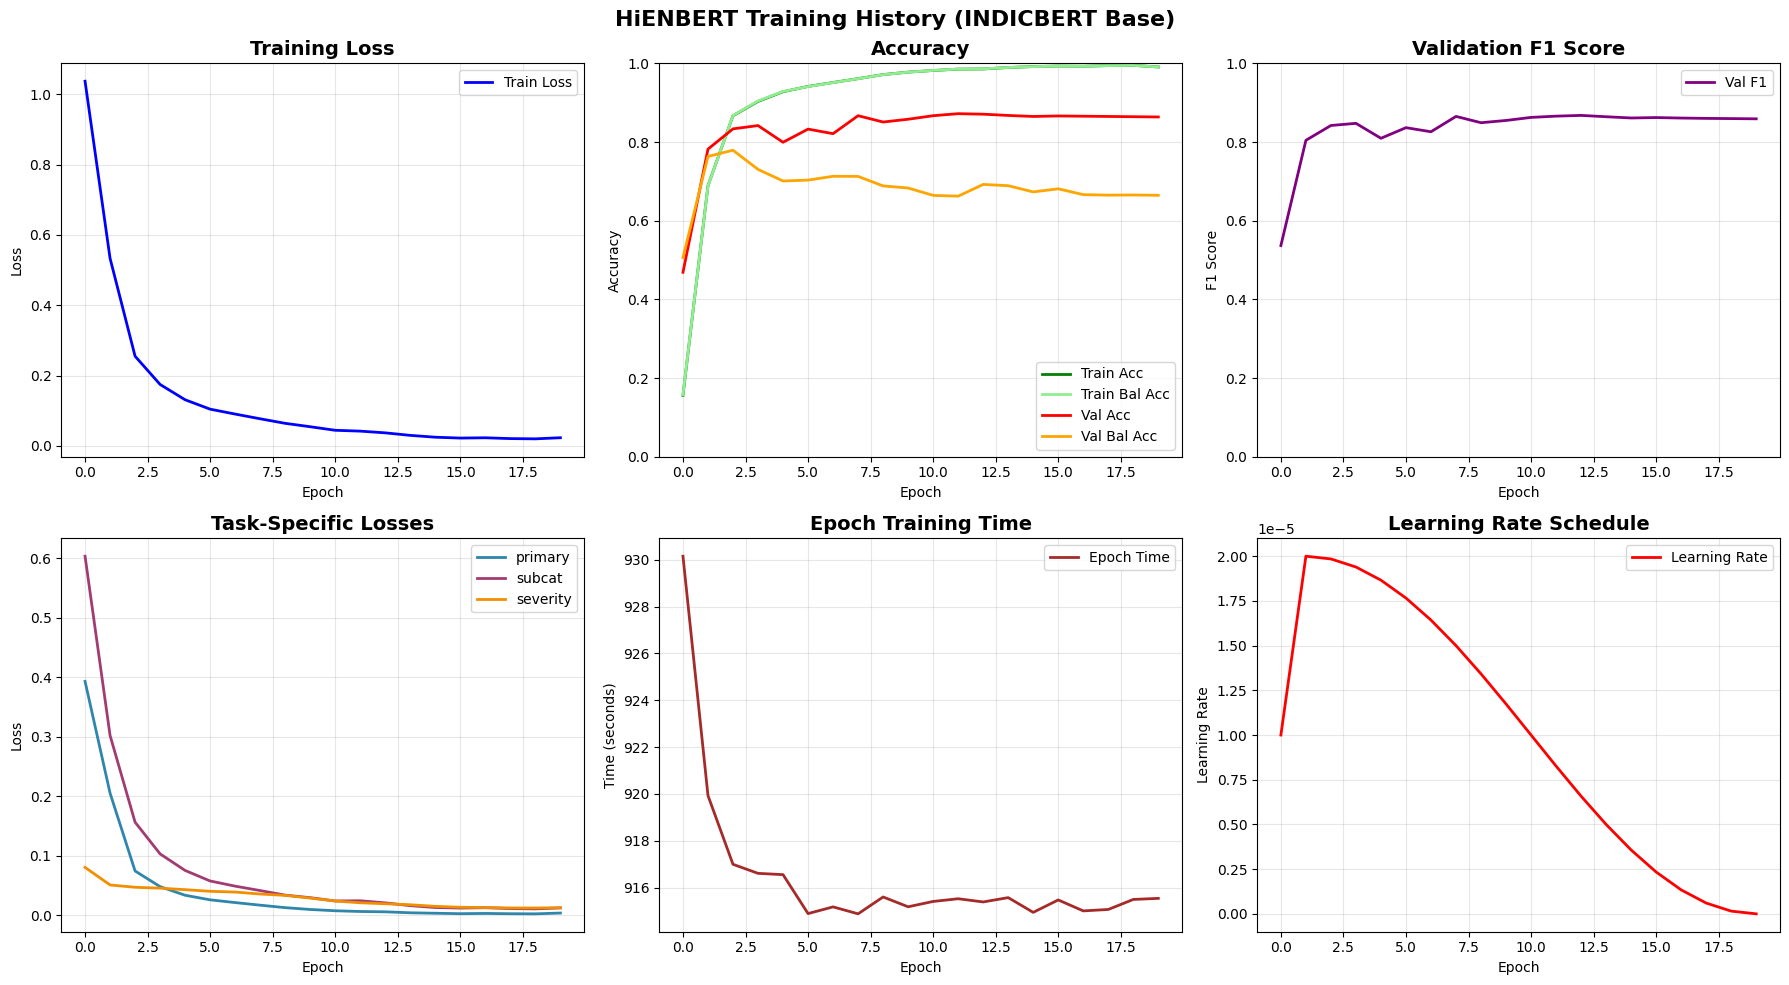

In [13]:
# ============================================================================
# CELL 13: TRAINING HISTORY VISUALIZATION
# ============================================================================

def plot_training_history(train_history, val_history, save_path=None):
    """Plot training and validation metrics"""
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    # Training loss
    axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2, color='blue')
    axes[0, 0].set_title('Training Loss', fontsize=14, fontweight='bold')
    axes[0, 0].set_xlabel('Epoch')
    axes[0, 0].set_ylabel('Loss')
    axes[0, 0].grid(True, alpha=0.3)
    axes[0, 0].legend()
    
    # Training accuracy
    axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2, color='green')
    axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2, color='lightgreen')
    axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2, color='red')
    axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2, color='orange')
    axes[0, 1].set_title('Accuracy', fontsize=14, fontweight='bold')
    axes[0, 1].set_xlabel('Epoch')
    axes[0, 1].set_ylabel('Accuracy')
    axes[0, 1].grid(True, alpha=0.3)
    axes[0, 1].legend()
    axes[0, 1].set_ylim(0, 1)
    
    # Validation F1
    axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
    axes[0, 2].set_title('Validation F1 Score', fontsize=14, fontweight='bold')
    axes[0, 2].set_xlabel('Epoch')
    axes[0, 2].set_ylabel('F1 Score')
    axes[0, 2].grid(True, alpha=0.3)
    axes[0, 2].legend()
    axes[0, 2].set_ylim(0, 1)
    
    # Task-specific losses
    task_names = ['primary', 'subcat', 'severity']
    colors = ['#2E86AB', '#A23B72', '#F18F01']
    for task, color in zip(task_names, colors):
        values = [h['task_losses'][task] for h in train_history]
        axes[1, 0].plot(values, label=task, linewidth=2, color=color)
    axes[1, 0].set_title('Task-Specific Losses', fontsize=14, fontweight='bold')
    axes[1, 0].set_xlabel('Epoch')
    axes[1, 0].set_ylabel('Loss')
    axes[1, 0].grid(True, alpha=0.3)
    axes[1, 0].legend()
    
    # Epoch time
    times = [h.get('time', 0) for h in train_history]
    axes[1, 1].plot(times, label='Epoch Time', linewidth=2, color='brown')
    axes[1, 1].set_title('Epoch Training Time', fontsize=14, fontweight='bold')
    axes[1, 1].set_xlabel('Epoch')
    axes[1, 1].set_ylabel('Time (seconds)')
    axes[1, 1].grid(True, alpha=0.3)
    axes[1, 1].legend()
    
    # Learning rate
    lrs = [h.get('lr', 0) for h in train_history]
    axes[1, 2].plot(lrs, label='Learning Rate', linewidth=2, color='red')
    axes[1, 2].set_title('Learning Rate Schedule', fontsize=14, fontweight='bold')
    axes[1, 2].set_xlabel('Epoch')
    axes[1, 2].set_ylabel('Learning Rate')
    axes[1, 2].grid(True, alpha=0.3)
    axes[1, 2].legend()
    
    plt.suptitle(f'HiENBERT Training History ({Config.BASE_MODEL.upper()} Base)', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot training history
plot_training_history(
    train_history, val_history,
    save_path=f"{Config.VISUALIZATION_DIR}/training_history.png"
)

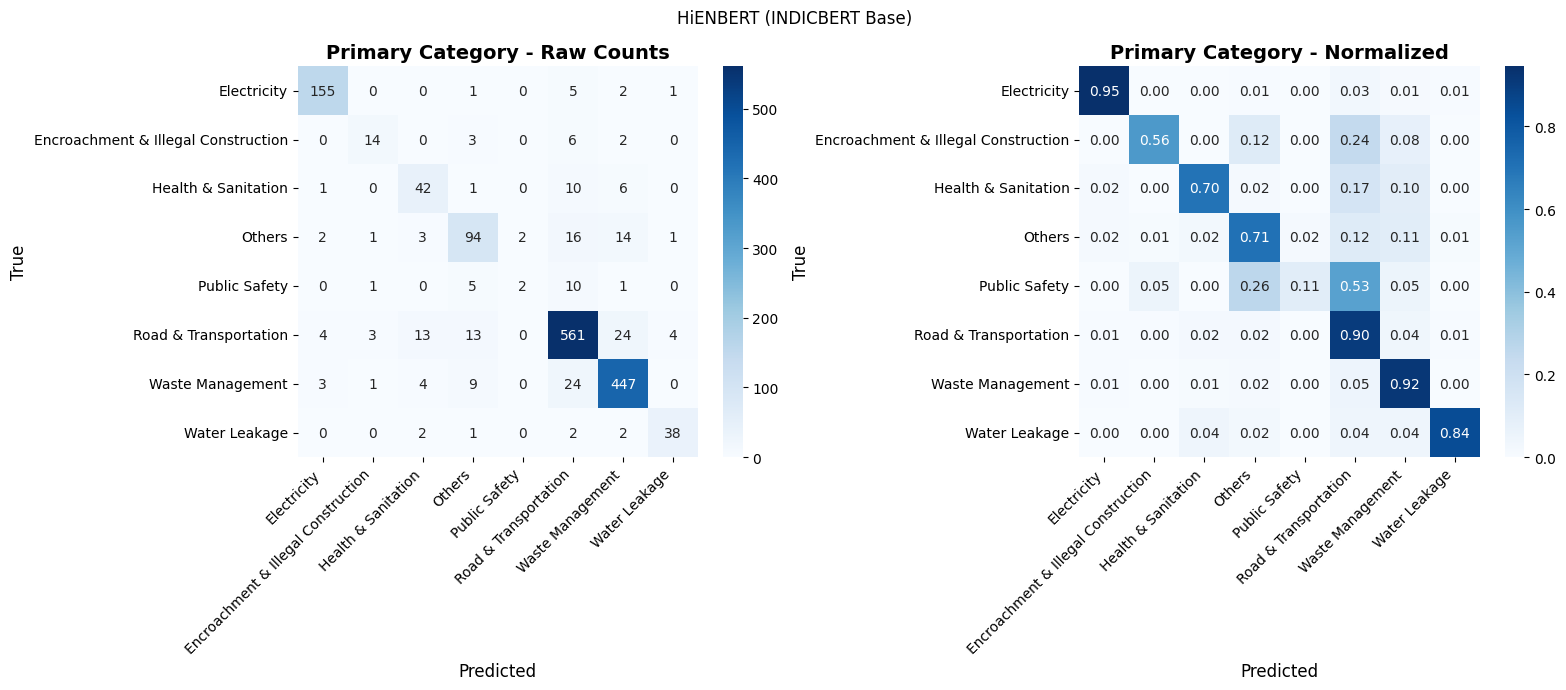

Getting severity predictions: 100%|██████████| 25/25 [00:05<00:00,  4.53it/s]


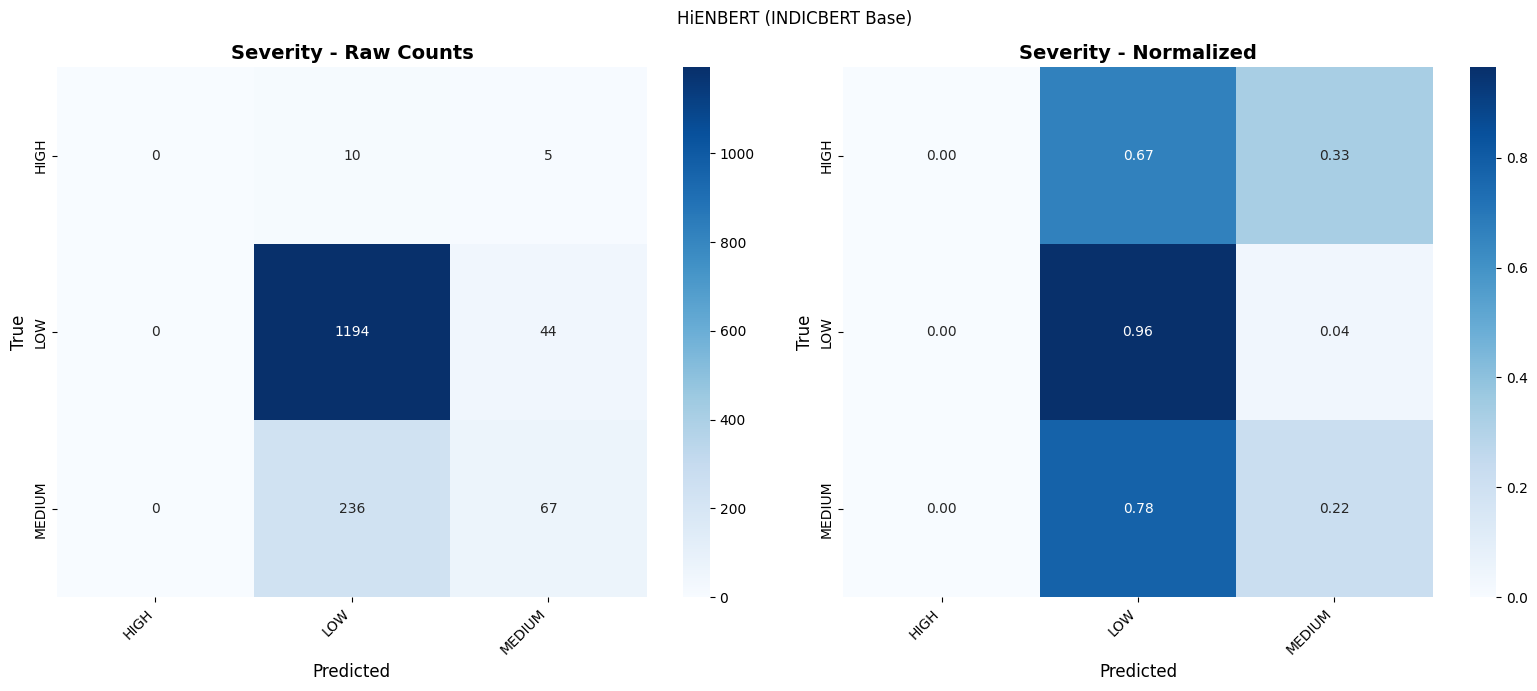

✅ Confusion matrices saved to: hienbert_indicbert_results/visualizations


In [14]:
# ============================================================================
# CELL 14: CONFUSION MATRIX VISUALIZATIONS
# ============================================================================

def plot_confusion_matrix(y_true, y_pred, class_names, title, save_path=None):
    """Plot confusion matrix with raw and normalized versions"""
    cm = confusion_matrix(y_true, y_pred)
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    cm_normalized = np.nan_to_num(cm_normalized)
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # Raw counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[0])
    axes[0].set_title(f'{title} - Raw Counts', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Predicted', fontsize=12)
    axes[0].set_ylabel('True', fontsize=12)
    axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')
    
    # Normalized
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[1])
    axes[1].set_title(f'{title} - Normalized', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Predicted', fontsize=12)
    axes[1].set_ylabel('True', fontsize=12)
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot confusion matrices
class_names = preprocessor.le_primary.classes_

plot_confusion_matrix(
    test_labels, test_preds, class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png"
)

# Get severity predictions for confusion matrix
model.eval()
severity_preds = []
severity_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Getting severity predictions"):
        input_ids = batch['input_ids'].to(Config.DEVICE)
        attention_mask = batch['attention_mask'].to(Config.DEVICE)
        sentiment = batch['sentiment'].to(Config.DEVICE)
        
        _, _, p3 = model(input_ids, attention_mask, sentiment)
        preds = torch.argmax(p3, dim=1)
        severity_preds.extend(preds.cpu().numpy())
        severity_labels.extend(batch['severity'].cpu().numpy())

severity_names = preprocessor.le_severity.classes_

plot_confusion_matrix(
    severity_labels, severity_preds, severity_names,
    'Severity',
    save_path=f"{Config.VISUALIZATION_DIR}/confusion_matrix_severity.png"
)

print(f"✅ Confusion matrices saved to: {Config.VISUALIZATION_DIR}")

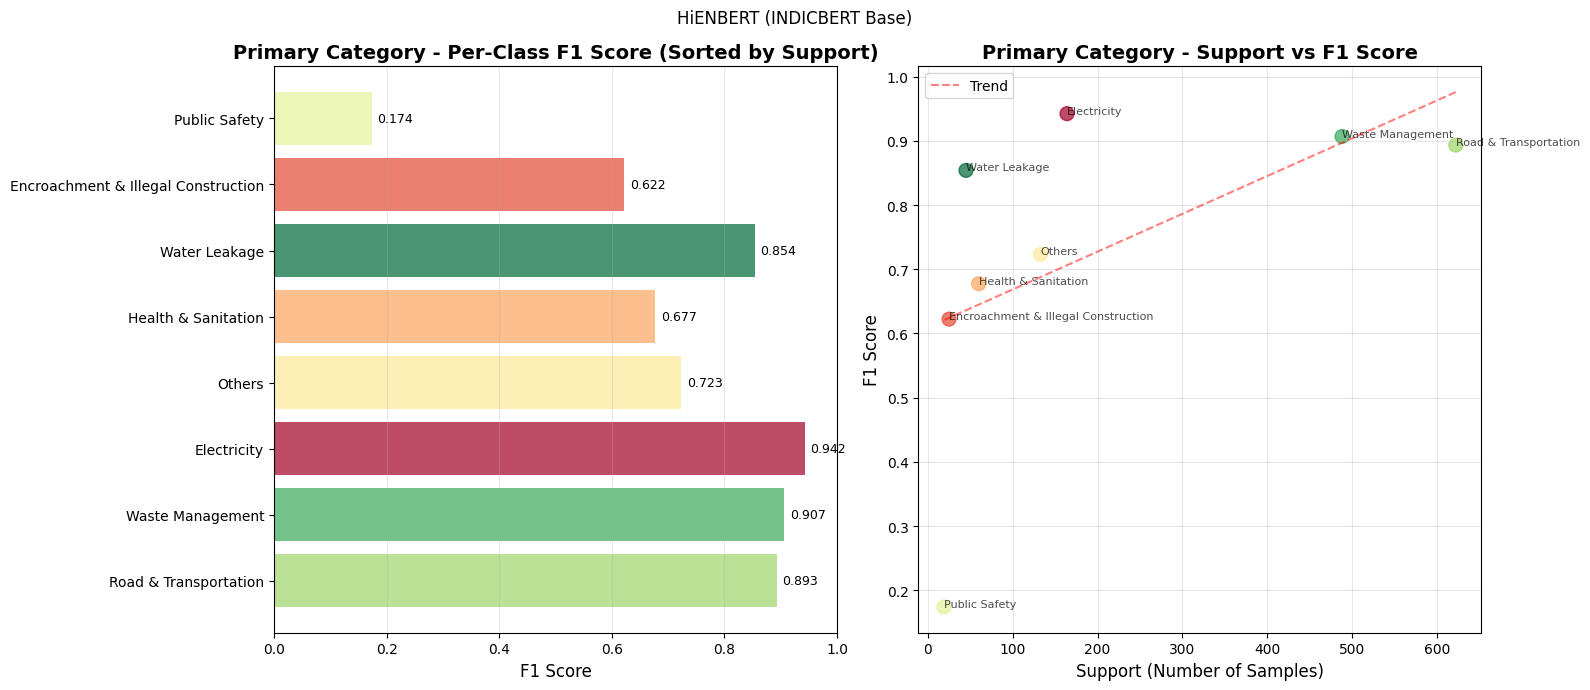

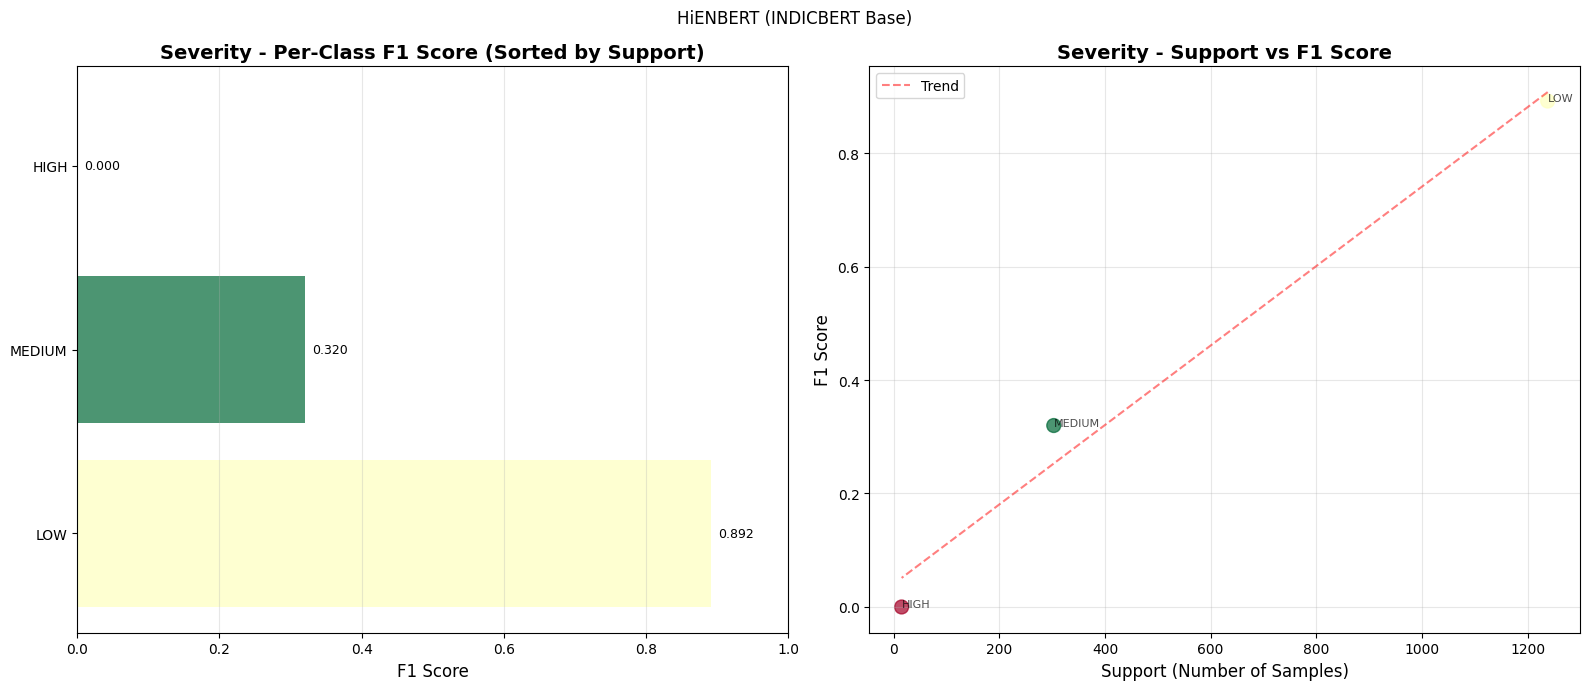

In [15]:
# ============================================================================
# CELL 15: PER-CLASS PERFORMANCE VISUALIZATION
# ============================================================================

def plot_per_class_performance(y_true, y_pred, class_names, title, save_path=None):
    """Visualize per-class performance metrics"""
    
    from sklearn.metrics import precision_recall_fscore_support
    
    precision, recall, f1, support = precision_recall_fscore_support(
        y_true, y_pred, average=None
    )
    
    sorted_indices = np.argsort(support)[::-1]
    class_names_sorted = [class_names[i] for i in sorted_indices]
    precision_sorted = [precision[i] for i in sorted_indices]
    recall_sorted = [recall[i] for i in sorted_indices]
    f1_sorted = [f1[i] for i in sorted_indices]
    support_sorted = [support[i] for i in sorted_indices]
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 7))
    
    # F1 scores
    colors = plt.cm.RdYlGn(np.linspace(0, 1, len(class_names)))[sorted_indices]
    bars = axes[0].barh(range(len(class_names)), f1_sorted, color=colors, alpha=0.7)
    axes[0].set_yticks(range(len(class_names)))
    axes[0].set_yticklabels(class_names_sorted, fontsize=10)
    axes[0].set_xlabel('F1 Score', fontsize=12)
    axes[0].set_title(f'{title} - Per-Class F1 Score (Sorted by Support)', fontsize=14, fontweight='bold')
    axes[0].set_xlim(0, 1)
    axes[0].grid(True, alpha=0.3, axis='x')
    
    for bar, val in zip(bars, f1_sorted):
        axes[0].text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                    f'{val:.3f}', va='center', fontsize=9)
    
    # Support vs F1 scatter
    axes[1].scatter(support_sorted, f1_sorted, alpha=0.7, s=100, c=colors)
    axes[1].set_xlabel('Support (Number of Samples)', fontsize=12)
    axes[1].set_ylabel('F1 Score', fontsize=12)
    axes[1].set_title(f'{title} - Support vs F1 Score', fontsize=14, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    
    # Add trend line
    z = np.polyfit(support_sorted, f1_sorted, 1)
    p = np.poly1d(z)
    axes[1].plot(support_sorted, p(support_sorted), "r--", alpha=0.5, label='Trend')
    
    # Annotate points with class names
    for i, (x, y, name) in enumerate(zip(support_sorted, f1_sorted, class_names_sorted)):
        axes[1].annotate(name, (x, y), fontsize=8, alpha=0.7)
    
    axes[1].legend()
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot per-class performance
plot_per_class_performance(
    test_labels, test_preds, class_names,
    'Primary Category',
    save_path=f"{Config.VISUALIZATION_DIR}/per_class_performance.png"
)

# Severity per-class performance
plot_per_class_performance(
    severity_labels, severity_preds, severity_names,
    'Severity',
    save_path=f"{Config.VISUALIZATION_DIR}/severity_per_class_performance.png"
)

Extracting embeddings for t-SNE...


Extracting embeddings: 100%|██████████| 25/25 [00:09<00:00,  2.68it/s]


Extracted 1556 embeddings of dimension 768
Applying t-SNE...


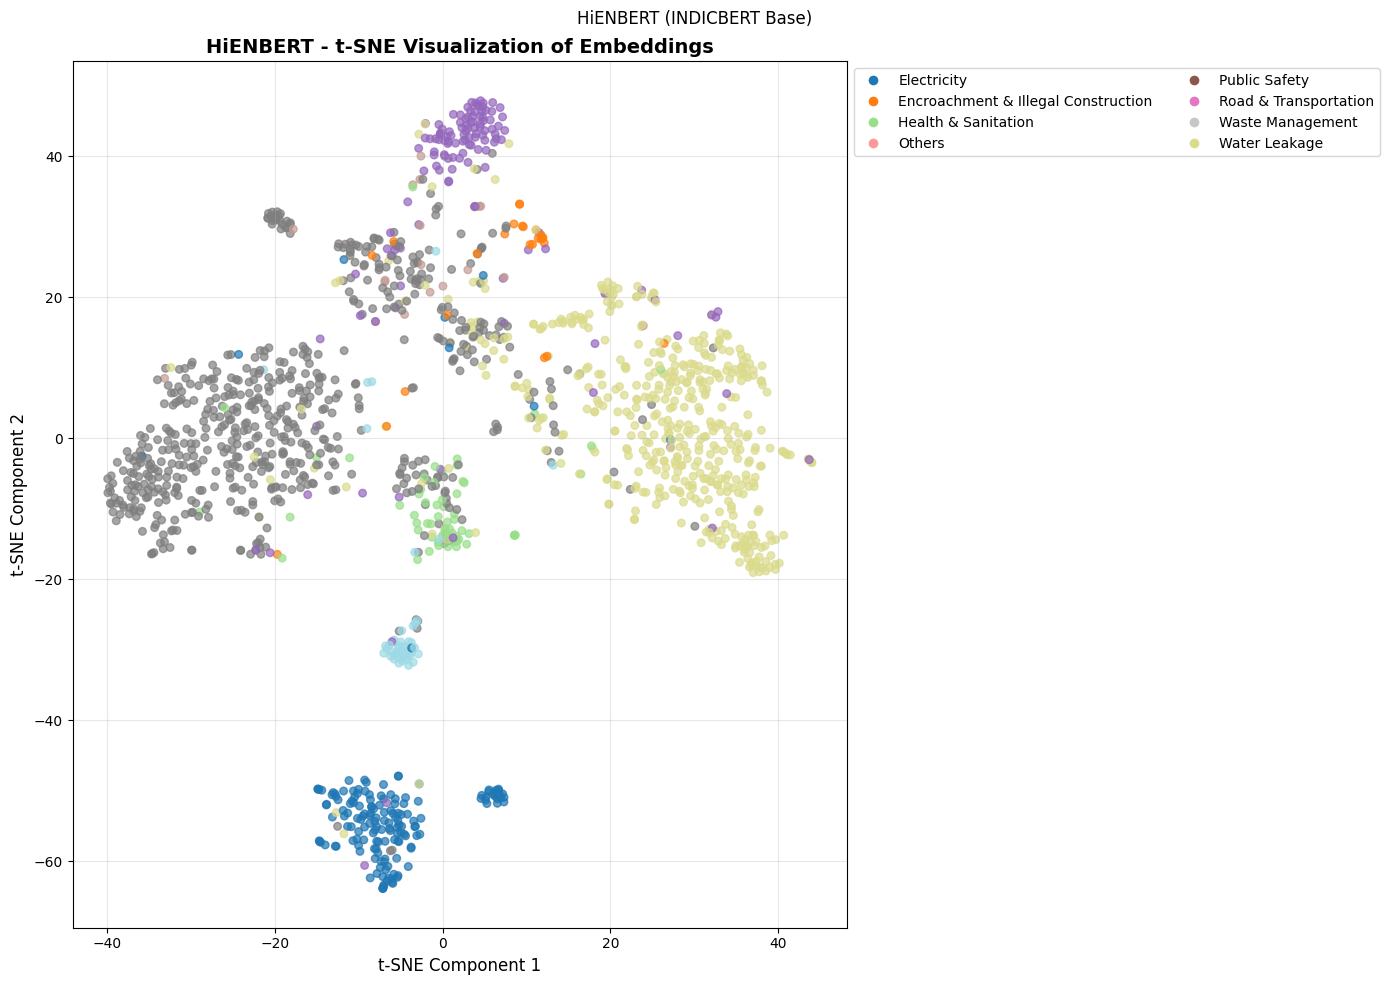

array([[-32.697838  ,  -4.647941  ],
       [ 11.128087  ,  29.574957  ],
       [ 23.34771   ,  13.34902   ],
       ...,
       [ 10.836385  ,  16.203833  ],
       [  0.69034487,  42.10887   ],
       [ 22.857187  , -11.489611  ]], shape=(1556, 2), dtype=float32)

In [16]:
# ============================================================================
# CELL 16: T-SNE EMBEDDING VISUALIZATION
# ============================================================================

def plot_tsne_embeddings(model, test_loader, class_names, device, title, save_path=None):
    """Create t-SNE visualization of embeddings"""
    print("Extracting embeddings for t-SNE...")
    
    model.eval()
    embeddings = []
    labels = []
    
    with torch.no_grad():
        for batch in tqdm(test_loader, desc="Extracting embeddings"):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            sentiment = batch['sentiment'].to(device)
            
            _, _, _ = model(input_ids, attention_mask, sentiment)
            outputs = model.base(input_ids=input_ids, attention_mask=attention_mask)
            cls_embedding = outputs.last_hidden_state[:, 0, :]
            embeddings.append(cls_embedding.cpu().numpy())
            labels.extend(batch['primary'].cpu().numpy())
    
    embeddings = np.vstack(embeddings)
    labels = np.array(labels)
    
    print(f"Extracted {embeddings.shape[0]} embeddings of dimension {embeddings.shape[1]}")
    
    # Sample if too many points for t-SNE
    if len(embeddings) > 2000:
        idx = np.random.choice(len(embeddings), 2000, replace=False)
        embeddings = embeddings[idx]
        labels = labels[idx]
    
    # Apply t-SNE
    print("Applying t-SNE...")
    tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000, verbose=0)
    embeddings_2d = tsne.fit_transform(embeddings)
    
    # Create visualization
    fig, ax = plt.subplots(figsize=(14, 10))
    
    scatter = ax.scatter(
        embeddings_2d[:, 0], embeddings_2d[:, 1],
        c=labels, cmap='tab20', alpha=0.7, s=30
    )
    
    ax.set_xlabel('t-SNE Component 1', fontsize=12)
    ax.set_ylabel('t-SNE Component 2', fontsize=12)
    ax.set_title(f'{title} - t-SNE Visualization of Embeddings', fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    
    # Add legend
    legend_elements = []
    for i, name in enumerate(class_names):
        if i < len(plt.cm.tab20.colors):
            legend_elements.append(
                plt.Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=plt.cm.tab20(i/len(class_names)),
                          label=name, markersize=8)
            )
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1), ncol=2)
    
    plt.suptitle(f'HiENBERT ({Config.BASE_MODEL.upper()} Base)', fontsize=12)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    return embeddings_2d

# Generate t-SNE visualization
plot_tsne_embeddings(
    model, test_loader, class_names, Config.DEVICE,
    'HiENBERT',
    save_path=f"{Config.VISUALIZATION_DIR}/tsne_embeddings.png"
)

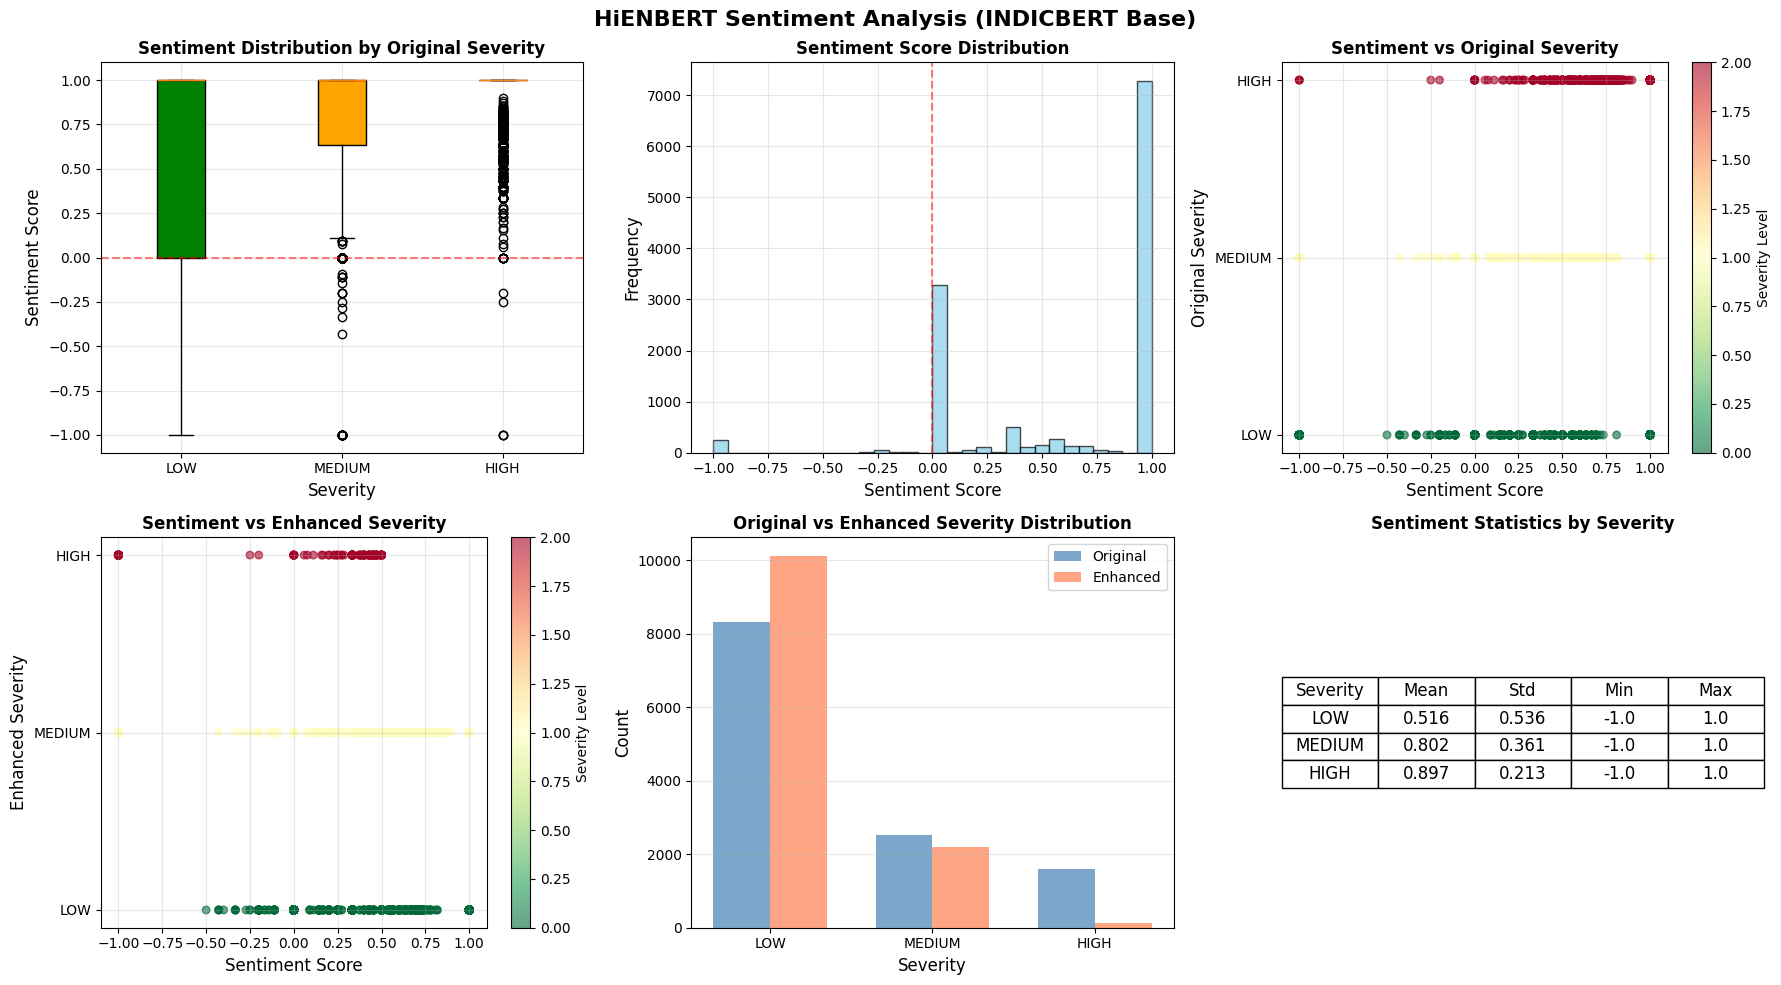

✅ Sentiment analysis saved to: hienbert_indicbert_results/visualizations/sentiment_analysis.png


In [17]:
# ============================================================================
# CELL 17: SENTIMENT ANALYSIS VISUALIZATION
# ============================================================================

def plot_sentiment_analysis(df, save_path=None):
    """Analyze and visualize sentiment patterns"""
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    
    severity_order = ['LOW', 'MEDIUM', 'HIGH']
    colors = ['green', 'orange', 'red']
    
    # 1. Sentiment distribution by severity
    sentiment_by_severity = [
        df[df['severity'] == s]['sentiment_score'].values 
        for s in severity_order
    ]
    
    bp = axes[0, 0].boxplot(sentiment_by_severity, labels=severity_order, patch_artist=True)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
    axes[0, 0].axhline(y=0, color='red', linestyle='--', alpha=0.5)
    axes[0, 0].set_xlabel('Severity', fontsize=12)
    axes[0, 0].set_ylabel('Sentiment Score', fontsize=12)
    axes[0, 0].set_title('Sentiment Distribution by Original Severity', fontweight='bold')
    axes[0, 0].grid(True, alpha=0.3)
    
    # 2. Sentiment distribution histogram
    axes[0, 1].hist(df['sentiment_score'], bins=30, color='skyblue', edgecolor='black', alpha=0.7)
    axes[0, 1].axvline(x=0, color='red', linestyle='--', alpha=0.5)
    axes[0, 1].set_xlabel('Sentiment Score', fontsize=12)
    axes[0, 1].set_ylabel('Frequency', fontsize=12)
    axes[0, 1].set_title('Sentiment Score Distribution', fontweight='bold')
    axes[0, 1].grid(True, alpha=0.3)
    
    # 3. Sentiment vs Severity Scatter (Original)
    scatter = axes[0, 2].scatter(
        df['sentiment_score'], 
        df['severity_encoded'],
        c=df['severity_encoded'],
        cmap='RdYlGn_r',
        alpha=0.6,
        s=30
    )
    axes[0, 2].set_xlabel('Sentiment Score', fontsize=12)
    axes[0, 2].set_ylabel('Original Severity', fontsize=12)
    axes[0, 2].set_yticks([0, 1, 2])
    axes[0, 2].set_yticklabels(['LOW', 'MEDIUM', 'HIGH'])
    axes[0, 2].set_title('Sentiment vs Original Severity', fontweight='bold')
    axes[0, 2].grid(True, alpha=0.3)
    plt.colorbar(scatter, label='Severity Level', ax=axes[0, 2])
    
    # 4. Sentiment vs Enhanced Severity Scatter
    if 'enhanced_severity' in df.columns:
        scatter = axes[1, 0].scatter(
            df['sentiment_score'], 
            df['enhanced_severity'],
            c=df['enhanced_severity'],
            cmap='RdYlGn_r',
            alpha=0.6,
            s=30
        )
        axes[1, 0].set_xlabel('Sentiment Score', fontsize=12)
        axes[1, 0].set_ylabel('Enhanced Severity', fontsize=12)
        axes[1, 0].set_yticks([0, 1, 2])
        axes[1, 0].set_yticklabels(['LOW', 'MEDIUM', 'HIGH'])
        axes[1, 0].set_title('Sentiment vs Enhanced Severity', fontweight='bold')
        axes[1, 0].grid(True, alpha=0.3)
        plt.colorbar(scatter, label='Severity Level', ax=axes[1, 0])
    
    # 5. Severity Distribution Comparison
    original_counts = df['severity'].value_counts()
    enhanced_counts = df['enhanced_severity_label'].value_counts() if 'enhanced_severity_label' in df.columns else original_counts
    
    x = np.arange(len(severity_order))
    width = 0.35
    
    bars1 = axes[1, 1].bar(x - width/2, 
                          [original_counts.get(s, 0) for s in severity_order], 
                          width, label='Original', color='steelblue', alpha=0.7)
    bars2 = axes[1, 1].bar(x + width/2, 
                          [enhanced_counts.get(s, 0) for s in severity_order], 
                          width, label='Enhanced', color='coral', alpha=0.7)
    
    axes[1, 1].set_xlabel('Severity', fontsize=12)
    axes[1, 1].set_ylabel('Count', fontsize=12)
    axes[1, 1].set_title('Original vs Enhanced Severity Distribution', fontweight='bold')
    axes[1, 1].set_xticks(x)
    axes[1, 1].set_xticklabels(severity_order)
    axes[1, 1].legend()
    axes[1, 1].grid(True, alpha=0.3, axis='y')
    
    # 6. Sentiment statistics by severity
    stats_data = []
    for severity in severity_order:
        scores = df[df['severity'] == severity]['sentiment_score']
        stats_data.append([
            severity,
            scores.mean(),
            scores.std(),
            scores.min(),
            scores.max()
        ])
    
    stats_df = pd.DataFrame(stats_data, columns=['Severity', 'Mean', 'Std', 'Min', 'Max'])
    axes[1, 2].axis('tight')
    axes[1, 2].axis('off')
    table = axes[1, 2].table(cellText=stats_df.round(3).values,
                            colLabels=stats_df.columns,
                            cellLoc='center',
                            loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    table.scale(1, 1.5)
    axes[1, 2].set_title('Sentiment Statistics by Severity', fontweight='bold')
    
    plt.suptitle(f'HiENBERT Sentiment Analysis ({Config.BASE_MODEL.upper()} Base)', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot sentiment analysis
plot_sentiment_analysis(
    train_df,
    save_path=f"{Config.VISUALIZATION_DIR}/sentiment_analysis.png"
)

print(f"✅ Sentiment analysis saved to: {Config.VISUALIZATION_DIR}/sentiment_analysis.png")

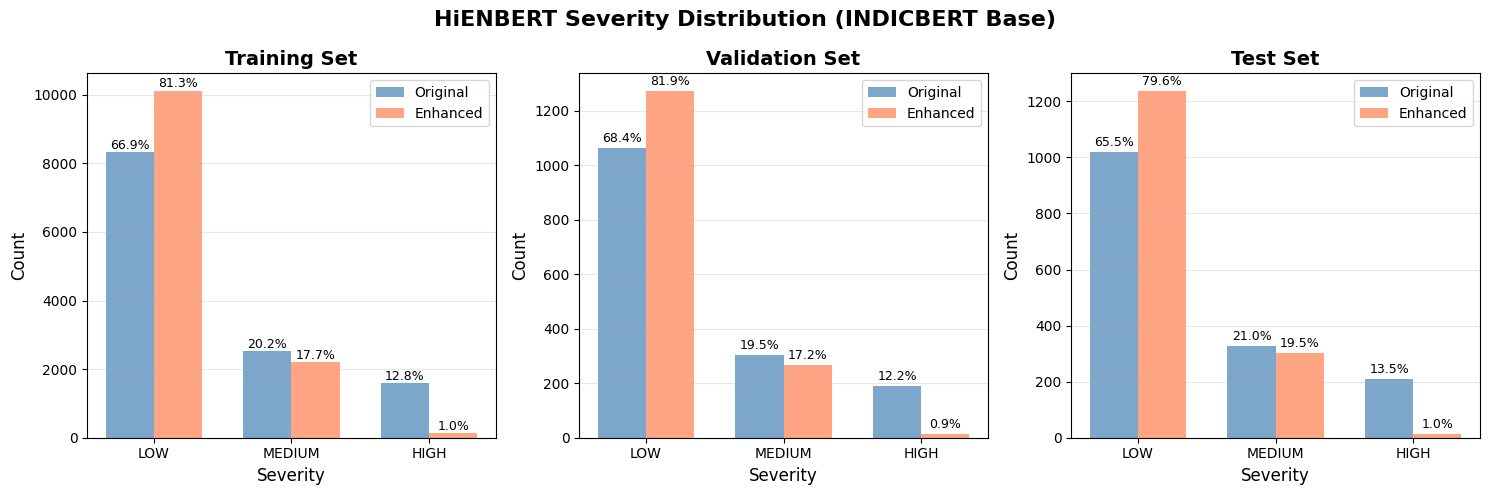

✅ Severity distribution saved to: hienbert_indicbert_results/visualizations/severity_distribution.png


In [18]:
# ============================================================================
# CELL 18: SEVERITY DISTRIBUTION VISUALIZATION
# ============================================================================

def plot_severity_distribution(train_df, dev_df, test_df, save_path=None):
    """Visualize severity distribution across datasets"""
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    severity_order = ['LOW', 'MEDIUM', 'HIGH']
    colors = ['green', 'orange', 'red']
    
    datasets = [
        ('Training', train_df),
        ('Validation', dev_df),
        ('Test', test_df)
    ]
    
    for ax, (name, df) in zip(axes, datasets):
        # Original severity
        original_counts = df['severity'].value_counts()
        original_pcts = df['severity'].value_counts(normalize=True) * 100
        
        # Enhanced severity (if available)
        if 'enhanced_severity_label' in df.columns:
            enhanced_counts = df['enhanced_severity_label'].value_counts()
            enhanced_pcts = df['enhanced_severity_label'].value_counts(normalize=True) * 100
        else:
            enhanced_counts = original_counts
            enhanced_pcts = original_pcts
        
        # Create grouped bar chart
        x = np.arange(len(severity_order))
        width = 0.35
        
        bars1 = ax.bar(x - width/2, 
                      [original_counts.get(s, 0) for s in severity_order], 
                      width, label='Original', color='steelblue', alpha=0.7)
        bars2 = ax.bar(x + width/2, 
                      [enhanced_counts.get(s, 0) for s in severity_order], 
                      width, label='Enhanced', color='coral', alpha=0.7)
        
        ax.set_xlabel('Severity', fontsize=12)
        ax.set_ylabel('Count', fontsize=12)
        ax.set_title(f'{name} Set', fontsize=14, fontweight='bold')
        ax.set_xticks(x)
        ax.set_xticklabels(severity_order)
        ax.legend()
        ax.grid(True, alpha=0.3, axis='y')
        
        # Add percentage labels
        for bar, pct in zip(bars1, [original_pcts.get(s, 0) for s in severity_order]):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, height + 10,
                   f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)
        
        for bar, pct in zip(bars2, [enhanced_pcts.get(s, 0) for s in severity_order]):
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2, height + 10,
                   f'{pct:.1f}%', ha='center', va='bottom', fontsize=9)
    
    plt.suptitle(f'HiENBERT Severity Distribution ({Config.BASE_MODEL.upper()} Base)', 
                fontsize=16, fontweight='bold')
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

# Plot severity distribution
plot_severity_distribution(
    train_df, dev_df, test_df,
    save_path=f"{Config.VISUALIZATION_DIR}/severity_distribution.png"
)

print(f"✅ Severity distribution saved to: {Config.VISUALIZATION_DIR}/severity_distribution.png")

In [19]:
# ============================================================================
# CELL 19: MODEL COMPARISON SUMMARY
# ============================================================================

def generate_model_comparison(test_metrics, best_val_f1, save_path=None):
    """Generate model comparison summary for IEEE Access paper"""
    
    print("\n" + "="*80)
    print("HIENBERT MODEL COMPARISON SUMMARY")
    print("="*80)
    
    print(f"\nBase Model: {Config.BASE_MODEL.upper()}")
    print(f"Model Path: {get_model_path()}")
    
    print("\n1. PERFORMANCE METRICS (Test Set):")
    print("-"*50)
    for metric, value in test_metrics.items():
        if isinstance(value, (int, float)) and metric != 'confidences':
            print(f"  {metric}: {value:.4f}")
    
    print(f"\n2. BEST VALIDATION PERFORMANCE:")
    print(f"  Best Validation F1: {best_val_f1:.4f}")
    print(f"  Best Validation Balanced Accuracy: {best_val_balanced_acc:.4f}")
    
    print(f"\n3. MODEL STATISTICS:")
    print(f"  Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"  Trainable Parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
    print(f"  Hidden Size: {model.hidden_size}")
    print(f"  Dropout Rate: {Config.DROPOUT}")
    print(f"  Max Sequence Length: {Config.MAX_LENGTH}")
    
    print(f"\n4. IMBALANCE HANDLING:")
    print(f"  Class Weights: {Config.USE_CLASS_WEIGHTS}")
    print(f"  Focal Loss: {Config.USE_FOCAL_LOSS}")
    if Config.USE_FOCAL_LOSS:
        print(f"  Focal Alpha: {Config.FOCAL_ALPHA}")
        print(f"  Focal Gamma: {Config.FOCAL_GAMMA}")
    print(f"  Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")
    
    print(f"\n5. TRAINING SETTINGS:")
    print(f"  Epochs: {Config.EPOCHS}")
    print(f"  Batch Size: {Config.BATCH_SIZE}")
    print(f"  Learning Rate: {Config.LEARNING_RATE}")
    print(f"  Weight Decay: {Config.WEIGHT_DECAY}")
    print(f"  Mixed Precision: {Config.USE_AMP}")
    
    # Create comparison table
    comparison_data = {
        'Metric': ['Accuracy', 'Balanced Accuracy', 'F1-Macro', 'F1-Weighted', 
                  'Precision', 'Recall', 'Cohen\'s Kappa', 'Matthews CC'],
        'Value': [
            test_metrics['accuracy'],
            test_metrics['balanced_accuracy'],
            test_metrics['f1_macro'],
            test_metrics['f1_weighted'],
            test_metrics['precision'],
            test_metrics['recall'],
            test_metrics['cohen_kappa'],
            test_metrics['mcc']
        ]
    }
    
    comparison_df = pd.DataFrame(comparison_data)
    print("\n6. COMPARISON TABLE:")
    print(comparison_df.to_string(index=False))
    
    # Save to CSV
    comparison_df.to_csv(f"{Config.RESULTS_DIR}/model_comparison.csv", index=False)
    print(f"\n✅ Comparison table saved to: {Config.RESULTS_DIR}/model_comparison.csv")
    
    return comparison_df

# Generate comparison summary
comparison_df = generate_model_comparison(test_metrics, best_val_f1)


HIENBERT MODEL COMPARISON SUMMARY

Base Model: INDICBERT
Model Path: ai4bharat/indic-bert

1. PERFORMANCE METRICS (Test Set):
--------------------------------------------------
  accuracy: 0.8695
  balanced_accuracy: 0.7099
  f1_macro: 0.7241
  f1_weighted: 0.8655
  precision: 0.8651
  recall: 0.8695
  cohen_kappa: 0.8178
  mcc: 0.8179

2. BEST VALIDATION PERFORMANCE:
  Best Validation F1: 0.8677
  Best Validation Balanced Accuracy: 0.6922

3. MODEL STATISTICS:
  Total Parameters: 34,063,401
  Trainable Parameters: 34,063,401
  Hidden Size: 768
  Dropout Rate: 0.3
  Max Sequence Length: 128

4. IMBALANCE HANDLING:
  Class Weights: True
  Focal Loss: True
  Focal Alpha: 0.25
  Focal Gamma: 2.0
  Weighted Sampler: True

5. TRAINING SETTINGS:
  Epochs: 20
  Batch Size: 32
  Learning Rate: 2e-05
  Weight Decay: 0.01
  Mixed Precision: True

6. COMPARISON TABLE:
           Metric    Value
         Accuracy 0.869537
Balanced Accuracy 0.709939
         F1-Macro 0.724102
      F1-Weighted 0.8

In [20]:
# ============================================================================
# CELL 20: COMPLETE SUMMARY REPORT
# ============================================================================

def generate_summary_report():
    """Generate comprehensive summary report"""
    
    print("\n" + "="*80)
    print(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)")
    print("="*80)
    
    # 1. Dataset Statistics
    print("\n1. DATASET STATISTICS:")
    print(f"   Training samples: {len(train_df)}")
    print(f"   Validation samples: {len(dev_df)}")
    print(f"   Test samples: {len(test_df)}")
    print(f"   Primary categories: {len(preprocessor.le_primary.classes_)}")
    print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
    print(f"   Severity levels: {len(preprocessor.le_severity.classes_)}")
    
    # 2. Model Architecture
    print("\n2. MODEL ARCHITECTURE:")
    print(f"   Base Model: {Config.BASE_MODEL.upper()}")
    print(f"   Model Path: {get_model_path()}")
    print(f"   Hidden Size: {model.hidden_size}")
    print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"   Dropout Rate: {Config.DROPOUT}")
    print(f"   Max Sequence Length: {Config.MAX_LENGTH}")
    
    # 3. Imbalance Handling
    print("\n3. IMBALANCE HANDLING:")
    print(f"   Class Weights: {Config.USE_CLASS_WEIGHTS}")
    print(f"   Focal Loss: {Config.USE_FOCAL_LOSS}")
    if Config.USE_FOCAL_LOSS:
        print(f"   Focal Alpha: {Config.FOCAL_ALPHA}")
        print(f"   Focal Gamma: {Config.FOCAL_GAMMA}")
    print(f"   Weighted Sampler: {Config.USE_WEIGHTED_SAMPLER}")
    
    # 4. Training Details
    print("\n4. TRAINING DETAILS:")
    print(f"   Epochs: {Config.EPOCHS}")
    print(f"   Batch Size: {Config.BATCH_SIZE}")
    print(f"   Learning Rate: {Config.LEARNING_RATE}")
    print(f"   Weight Decay: {Config.WEIGHT_DECAY}")
    print(f"   Mixed Precision: {Config.USE_AMP}")
    
    # 5. Test Performance
    print("\n5. TEST SET PERFORMANCE:")
    for metric, value in test_metrics.items():
        if isinstance(value, (int, float)) and metric != 'confidences':
            print(f"   {metric}: {value:.4f}")
    
    # 6. Best Validation Performance
    print("\n6. BEST VALIDATION PERFORMANCE:")
    print(f"   Best Validation F1: {best_val_f1:.4f}")
    print(f"   Best Validation Balanced Accuracy: {best_val_balanced_acc:.4f}")
    
    # 7. Training History
    print("\n7. TRAINING HISTORY:")
    print(f"   Final Train Loss: {train_history[-1]['loss']:.4f}")
    print(f"   Final Train Accuracy: {train_history[-1]['acc']:.4f}")
    print(f"   Final Train Balanced Accuracy: {train_history[-1]['balanced_acc']:.4f}")
    
    # 8. Severity Distribution
    print("\n8. SEVERITY DISTRIBUTION (Training):")
    severity_dist = train_df['severity'].value_counts()
    severity_pct = train_df['severity'].value_counts(normalize=True) * 100
    for severity in ['LOW', 'MEDIUM', 'HIGH']:
        print(f"   {severity}: {severity_dist.get(severity, 0)} ({severity_pct.get(severity, 0):.1f}%)")
    
    # 9. Saved Files
    print("\n9. SAVED FILES:")
    print(f"   Best Model: {Config.MODEL_DIR}/best_hienbert_model.pt")
    print(f"   Final Model: {Config.MODEL_DIR}/hienbert_model.pt")
    print(f"   Encoders: {Config.MODEL_DIR}/le_*.pkl")
    print(f"   Test Results: {Config.RESULTS_DIR}/test_results.json")
    print(f"   Comparison Table: {Config.RESULTS_DIR}/model_comparison.csv")
    print(f"   Visualizations: {Config.VISUALIZATION_DIR}/")
    
    print("\n" + "="*80)
    print("END OF SUMMARY REPORT")
    print("="*80)
    
    # Save report to file
    with open(f"{Config.RESULTS_DIR}/summary_report.txt", 'w') as f:
        f.write(f"HIENBERT COMPREHENSIVE SUMMARY REPORT ({Config.BASE_MODEL.upper()} Base)\n")
        f.write("="*80 + "\n\n")
        # Write all the above information to file
        # ... (similar content as printed)

# Generate summary report
generate_summary_report()

print(f"\n✅ All results saved to: {Config.BASE_DIR}")
print(f"📁 Results directory: {Config.RESULTS_DIR}")
print(f"📁 Visualizations directory: {Config.VISUALIZATION_DIR}")
print(f"📁 Models directory: {Config.MODEL_DIR}")
print(f"\n{'='*80}")
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print(f"Base Model: {Config.BASE_MODEL.upper()}")
print("="*80)


HIENBERT COMPREHENSIVE SUMMARY REPORT (INDICBERT Base)

1. DATASET STATISTICS:
   Training samples: 12441
   Validation samples: 1555
   Test samples: 1556
   Primary categories: 8
   Subcategories: 27
   Severity levels: 3

2. MODEL ARCHITECTURE:
   Base Model: INDICBERT
   Model Path: ai4bharat/indic-bert
   Hidden Size: 768
   Total Parameters: 34,063,401
   Dropout Rate: 0.3
   Max Sequence Length: 128

3. IMBALANCE HANDLING:
   Class Weights: True
   Focal Loss: True
   Focal Alpha: 0.25
   Focal Gamma: 2.0
   Weighted Sampler: True

4. TRAINING DETAILS:
   Epochs: 20
   Batch Size: 32
   Learning Rate: 2e-05
   Weight Decay: 0.01
   Mixed Precision: True

5. TEST SET PERFORMANCE:
   accuracy: 0.8695
   balanced_accuracy: 0.7099
   f1_macro: 0.7241
   f1_weighted: 0.8655
   precision: 0.8651
   recall: 0.8695
   cohen_kappa: 0.8178
   mcc: 0.8179

6. BEST VALIDATION PERFORMANCE:
   Best Validation F1: 0.8677
   Best Validation Balanced Accuracy: 0.6922

7. TRAINING HISTORY:
   Fi